In [2]:
import numpy as np

from tellurics.training import TelluricTrainingModule
from tellurics.data import datamodule

from tellurics.data.splits import split_night_indices_order, split_night_indices
from tellurics.config.data import DataConfig
from tellurics.config.experiment import ExperimentConfig
from tellurics.config.paths import expand_env_vars
from pathlib import Path

from tellurics.data.scaling import ParameterScaler
from tellurics.data.datamodule import TelluricDataModule, build_scaler


In [3]:
!pwd

/home/mvasist/Tellurics/tests


In [4]:
import os
# os.environ["TELLURICS_DATA"] = "/home/mvasist/Documents/Tellurics_data"


In [5]:
parent = Path.cwd().parent
print(parent)

/home/mvasist/Tellurics


In [6]:
# load config 

import torch
import yaml

repo_root = Path.cwd().parent
print(repo_root)
path =  repo_root / Path('experiments/experiment1_smoke.yaml')                     
raw = yaml.safe_load(path.read_text()) or {}
raw = expand_env_vars(raw)
print(raw)
config = ExperimentConfig(**raw)

run_dir = repo_root / config.run_dir
ckpt_dir = run_dir / config.training.checkpoint_dir / "neural_telluric_predictor"
# ckpts = sorted(ckpt_dir.glob("*.ckpt"), key=lambda p: p.stat().st_mtime)
# ckpt_path = ckpts[-1]  
ckpt_path = ckpt_dir / "estimator-epoch=019-validation_loss=0.0570.ckpt"
print("loading checkpoint:", ckpt_path)                    

scaler = build_scaler(config.data)
training_module = TelluricTrainingModule(config.model, config.training, scaler=scaler)

ckpt = torch.load(ckpt_path, map_location="cpu", weights_only=False)
training_module.load_state_dict(ckpt["state_dict"])
training_module.eval()



/home/mvasist/Tellurics
{'run_dir': 'runs/experiment1_smoke', 'wandb': {'project': 'neural_telluric_predictor', 'title': 'experiment1_smoke'}, 'model': {'architecture': 'neural_telluric_predictor', 'num_wavelength_bins': 51557, 'n_frames_per_series': 73, 'num_queries': 16, 'spectral_latent_dim': 64, 'metadata_dim': 3, 'metadata_enc_dim': 16, 'metadata_enc_hidden': None, 'time_enc_dim': 16, 'param_dim': 16, 'param_decoder_hidden': None, 'param_activation': 'sigmoid', 'num_heads': 4, 'dropout': 0.1, 'x_encoder_channels': [16, 32, 64, 96, 128], 'x_encoder_kernel': 7, 'x_encoder_stride': 2, 's_encoder_channels': [16, 32, 64], 's_encoder_kernel': 7, 's_encoder_stride': 2, 'encoder_pool_bins': 16, 'fusion_hidden': 0, 'fusion_layers': 2}, 'data': {'root': '/scratch/mvasist/Tellurics_data', 'night_h5': 'telluric_timeseries/telluric_templates_nights.h5', 'phoenix_dir': 'phoenix/convolved', 'stellar_scale': True, 'scale_metadata': True, 'scale_params': True, 'scale_time': True, 'param_bounds': {

[10/28/26 13:23:44] INFO     TelluricTrainingModule: NeuralTelluricPredictor with 2,646,160 trainable parameters

TelluricTrainingModule(
  (model): NeuralTelluricPredictor(
    (spectral_encoder): SpectralEncoder(
      (stack): Sequential(
        (0): Conv1d(1, 16, kernel_size=(7,), stride=(2,), padding=(3,))
        (1): GroupNorm(1, 16, eps=1e-05, affine=True, bias=True)
        (2): GELU(approximate='none')
        (3): Dropout(p=0.1, inplace=False)
        (4): Conv1d(16, 32, kernel_size=(7,), stride=(2,), padding=(3,))
        (5): GroupNorm(1, 32, eps=1e-05, affine=True, bias=True)
        (6): GELU(approximate='none')
        (7): Dropout(p=0.1, inplace=False)
        (8): Conv1d(32, 64, kernel_size=(7,), stride=(2,), padding=(3,))
        (9): GroupNorm(1, 64, eps=1e-05, affine=True, bias=True)
        (10): GELU(approximate='none')
        (11): Dropout(p=0.1, inplace=False)
        (12): Conv1d(64, 96, kernel_size=(7,), stride=(2,), padding=(3,))
        (13): GroupNorm(1, 96, eps=1e-05, affine=True, bias=True)
        (14): GELU(approximate='none')
        (15): Dropout(p=0.1, inplac

In [7]:
## load one sample from the test set 

import h5py

DATA_DIR = config.data.night_h5 
print("loading data from", DATA_DIR)
TEMPLATES_H5 = DATA_DIR / config.data.night_h5

n_nights = config.data.max_nights
train_ids, val_ids, test_ids = split_night_indices_order(
            n_nights,
            config.data.train_fraction,
            config.data.val_fraction,
            config.data.seed,
        )

with h5py.File(TEMPLATES_H5, "r") as f:
    labels = f["labels"][test_ids[0]]
    transmission = f["transmission"][test_ids[0], :, :]
    wavelength = f["wavelength"][:]
    columns = f["labels"].attrs["columns"]



loading data from /scratch/mvasist/Tellurics_data/telluric_timeseries/telluric_templates_nights.h5


In [8]:
## predict the tellurics 

data_module = TelluricDataModule(
    config.data,
    run_dir=run_dir,       # needed: _assign_stars() writes stellar_assignment.csv there
    batch_size=4,          
    num_workers=0,         
)
data_module.setup() 

import torch
import torch.nn.functional as F

test_loader = data_module.test_dataloader()     
batch = next(iter(test_loader))

device = next(training_module.parameters()).device
training_module.eval()

observed = batch["observed"].to(device)
stellar  = batch["stellar"].to(device)
metadata = batch["theta"]["metadata"].to(device)
time     = batch["theta"]["time"].to(device)

with torch.no_grad():
    out_norm = training_module(observed, stellar=stellar, metadata=metadata, time=time)
    pred_norm = out_norm.params                    # (B, T, P) in [0, 1]
    out_phys  = training_module.to_physical(out_norm)
    pred_phys = out_phys.params                    # (B, T, P) physical units

[10/28/26 13:23:46] WARNING  data.max_nights=10: using only the first 10 of 10000 nights (smoke/debug subset).

                    INFO     10 nights x 73 frames from                                                            
                             /scratch/mvasist/Tellurics_data/telluric_timeseries/telluric_templates_nights.h5

[10/28/26 13:23:47] INFO     train 8 / val 1 / test 1; stellar audit ->                                            
                             /home/mvasist/Tellurics/runs/experiment1_smoke/stellar_assignment.csv

/scratch/mvasist/miniconda3/envs/tellurics/lib/python3.10/site-packages/torch/cuda/__init__.py:1174: UserWarning: Can't initialize NVML
  raw_cnt = _raw_device_count_nvml()
/scratch/mvasist/miniconda3/envs/tellurics/lib/python3.10/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


In [9]:
target = batch["theta"]["output_params"].to(device)          # (B, T, P), [0, 1]
mse    = F.mse_loss(pred_norm, target)
rmse   = mse.sqrt()
print(f"MSE {mse.item():.3e}  RMSE {rmse.item():.3e}")

# per-parameter RMSE, to see which gas dominates the error
from tellurics.data.datasets.timeseries import TARGET_COLUMNS
per_param = (pred_norm - target).pow(2).mean(dim=(0, 1)).sqrt()
for name, value in zip(TARGET_COLUMNS, per_param.tolist()):
    print(f"{name:>12s}: {value:.3e}")

MSE 1.752e-02  RMSE 1.324e-01
    pressure: 1.691e-02
 temperature: 4.941e-02
    humidity: 7.563e-02
       angle: 1.563e-01
     airmass: 2.209e-01
         co2: 7.837e-02
          o3: 1.076e-01
         n2o: 2.123e-01
          co: 1.190e-01
         ch4: 5.539e-02
          o2: 1.146e-01
          no: 1.056e-01
         so2: 1.516e-01
         no2: 1.264e-01
         nh3: 2.118e-01
        hno3: 1.028e-01


In [10]:
# from telfit import Modeler

# sim = TelluricSimulation(
#     observatory=conditions.observatory,
#     modeler=Modeler(print_lblrtm_output=False, debug=False),
# )

In [11]:
# %pip install lockfile


In [12]:
import os, sys

os.environ.setdefault("TELFIT_HOME", "/scratch/mvasist/Tellurics_data/telfit")

from tellurics.simulation.utils.telfit_home import add_telfit_to_path
print(add_telfit_to_path())      # /scratch/mvasist/Tellurics_data/telfit/src

import telfit

from pathlib import Path
from tellurics.simulation.telluric.model import TelluricSimulation
from tellurics.simulation.telluric.conditions import ConditionSeries

conditions = ConditionSeries(
    Path("/scratch/mvasist/Tellurics_data/telluric_timeseries/telfit_condition_series.h5")
)

sim = TelluricSimulation(
    observatory=conditions.observatory,
    modeler=telfit.Modeler(
        print_lblrtm_output=False,
        debug=False,
        TelluricModelingDirRoot="/scratch/mvasist/Tellurics_data/.TelFit",
    ),
)

transmissions, labels = sim.simulate_series(conditions, start=0, stop=73)
print(transmissions.shape)

/scratch/mvasist/Tellurics_data/telfit/src


/scratch/mvasist/miniconda3/envs/tellurics/lib/python3.10/site-packages/pysynphot/__init__.py:8: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound
/scratch/mvasist/miniconda3/envs/tellurics/lib/python3.10/site-packages/pysynphot/locations.py:46: UserWarning: PYSYN_CDBS is undefined; functionality will be SEVERELY crippled.
  warnings.warn("PYSYN_CDBS is undefined; functionality will be SEVERELY "
/scratch/mvasist/miniconda3/envs/tellurics/lib/python3.10/site-packages/pysynphot/locations.py:345: UserWarning: Extinction files not found in extinction
  warnings.warn('Extinction files not found in %s' % (extdir, ))


Using default working directory.
Using default working directory.
Using default working directory.
Using default working directory.
Using default working directory.
Using default working directory.
Using default working directory.
Using default working directory.
Using default working directory.
Using default working directory.
Using default working directory.
Using default working directory.
Using default working directory.
Using default working directory.
Using default working directory.
Using default working directory.
Using default working directory.
Using default working directory.
Using default working directory.
Using default working directory.
Using default working directory.
Using default working directory.
Using default working directory.
Using default working directory.
Using default working directory.
Using default working directory.
Using default working directory.
Using default working directory.
Using default working directory.
Using default working directory.
Using defa

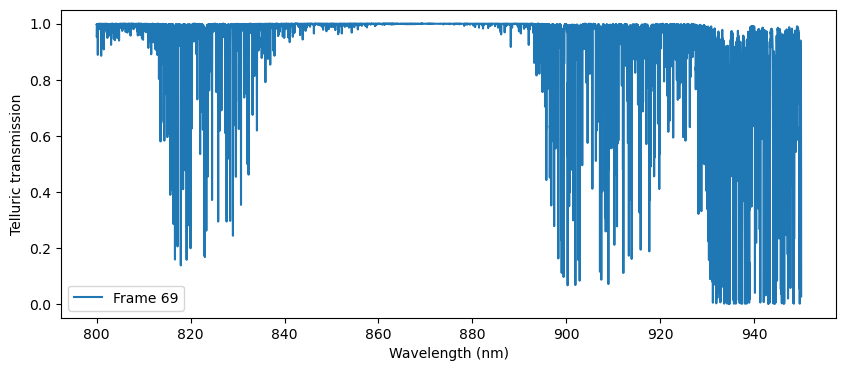

In [15]:
## compare the test tellurics sample with the predicted and simulated tellurics against one another by plotting them side by side
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 4))

for i in range(69, 73, 12):
    ax.plot(
        wavelength,
        transmissions[i],
        label=f"Frame {i}",
    )

ax.set_xlabel("Wavelength (nm)")
ax.set_ylabel("Telluric transmission")
ax.legend()
plt.show()

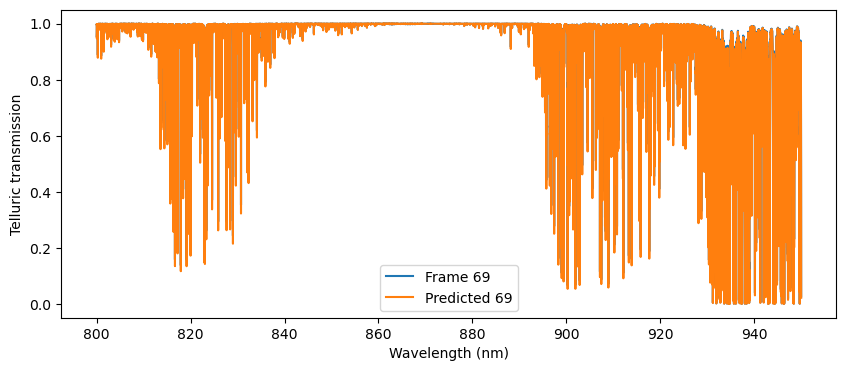

In [21]:
tellurics_test = observed/stellar

## Plotting comparison

fig, ax = plt.subplots(figsize=(10, 4))

for i in range(69, 73, 12):
    ax.plot(
        wavelength,
        transmissions[i],
        label=f"Frame {i}",
    )
    ax.plot(wavelength, tellurics_test[0, i].cpu().numpy(), label=f"Predicted {i}")

ax.set_xlabel("Wavelength (nm)")
ax.set_ylabel("Telluric transmission")
ax.legend()
plt.show()

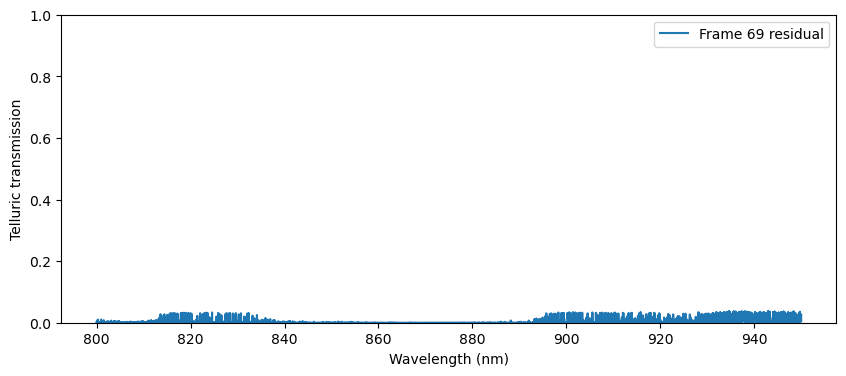

In [25]:
fig, ax = plt.subplots(figsize=(10, 4))

for i in range(69, 73, 12):
    ax.plot(
        wavelength,
        transmissions[i]- tellurics_test[0, i].cpu().numpy(),
        label=f"Frame {i} residual",

    )

ax.set_xlabel("Wavelength (nm)")
ax.set_ylabel("Telluric transmission")
ax.set_ylim(0,1)
ax.legend()
plt.show()

In [ ]:
## plot a zoomed-in version too and note the mse loss of the prediction in the title. 
